# Telecom Customer Churn — Complete Machine Learning Capstone

**Course:** 23CSE301 Machine Learning (2026–27)  
**Tracks:** Regression (10 algorithms), Classification (10 algorithms), Clustering (2 algorithms)

This notebook follows the supplied capstone rubric: data audit and EDA, missing-value detection and imputation, IQR outlier detection and training-only capping, feature engineering, consistent splits, model comparisons, tuning, cross-validation, and visualizations.

**Dataset note:** The supplied modified CSV deliberately contains missing values and injected numerical extremes for demonstrating cleaning. The notebook reports actual counts rather than assuming them. `MonthlyCharges` is the regression target (a continuous value); `Churn` is the classification target. Churn labels are not used to fit clustering models.

Run all cells from top to bottom. Some model searches and clustering visualizations may take several minutes.

## 1. Imports, reproducibility, and dataset loading

In [10]:
import os, warnings, sys, subprocess, importlib.util
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score,
    davies_bouldin_score, calinski_harabasz_score)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
    RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier)
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram


df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn_with_missing_outliers.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data audit and missing-value detection

In [3]:
print("Rows, columns:", df.shape)
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
}).sort_values("Missing Count", ascending=False)
print("Missing-value report:")
display(missing_report)
print("Duplicate rows:", int(df.duplicated().sum()))
if "Churn" in df:
    print("Churn class distribution (including missing):")
    display(df["Churn"].value_counts(dropna=False).to_frame("Count"))
print("Numeric summary:")
display(df.describe(include="all").T)

Rows, columns: (7043, 21)

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,float64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Missing-value report:


,Missing Count,Missing Percent,Data Type
TotalCharges,16,0.23,float64
tenure,7,0.10,float64
MonthlyCharges,5,0.07,float64
PaymentMethod,4,0.06,object
Contract,4,0.06,object
gender,4,0.06,object
customerID,0,0.00,object
TechSupport,0,0.00,object
PaperlessBilling,0,0.00,object
StreamingMovies,0,0.00,object


Duplicate rows: 0
Churn class distribution (including missing):


,Count
Churn,
No,5174
Yes,1869


Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7039,2,Male,3552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7036.0,NaN,NaN,NaN,32.446134,25.020193,-20.0,9.0,29.0,55.0,365.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)

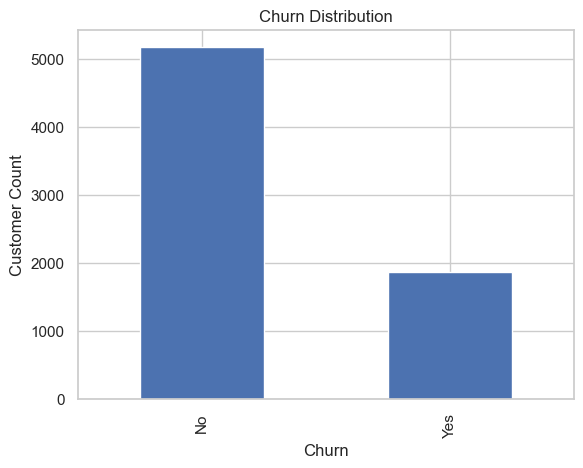

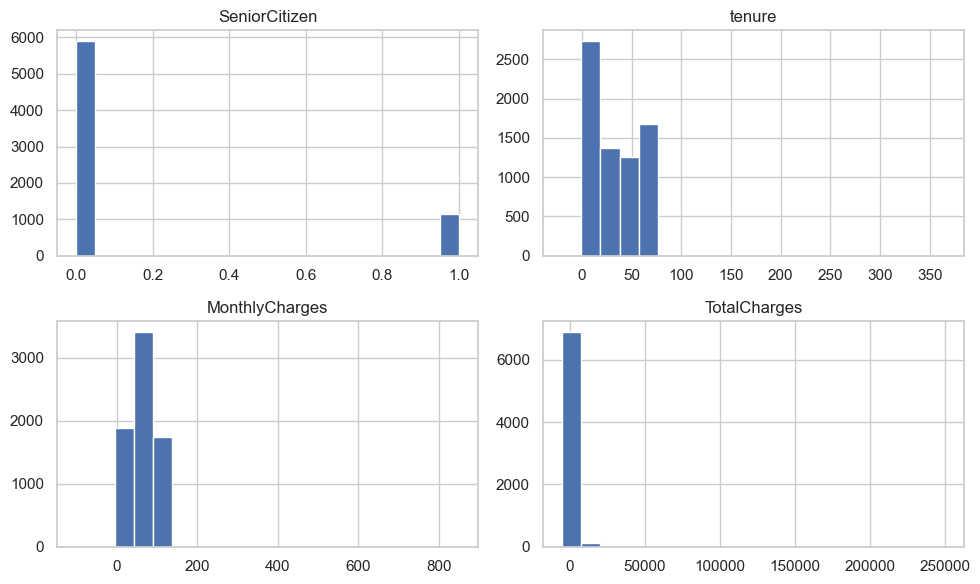

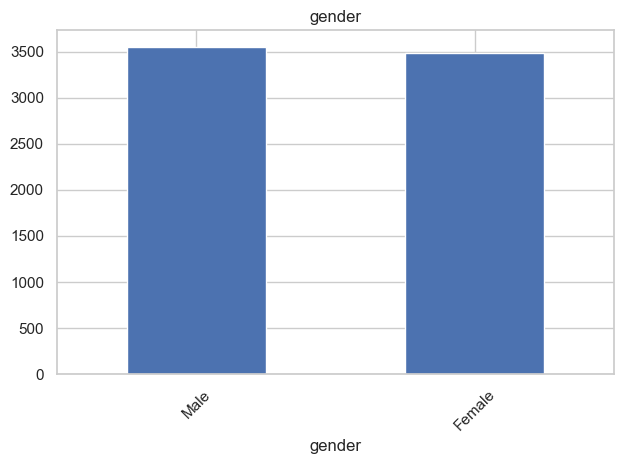

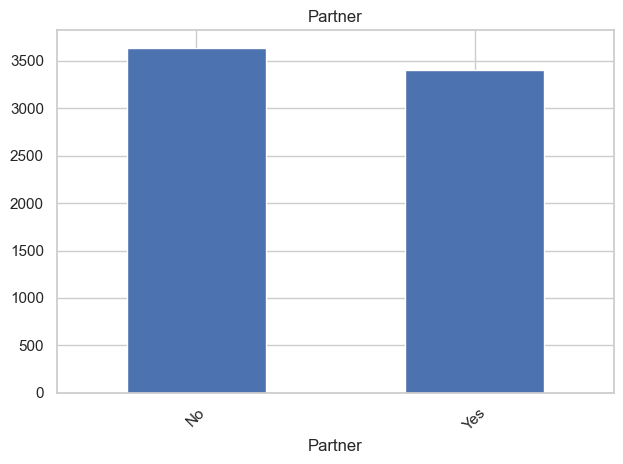

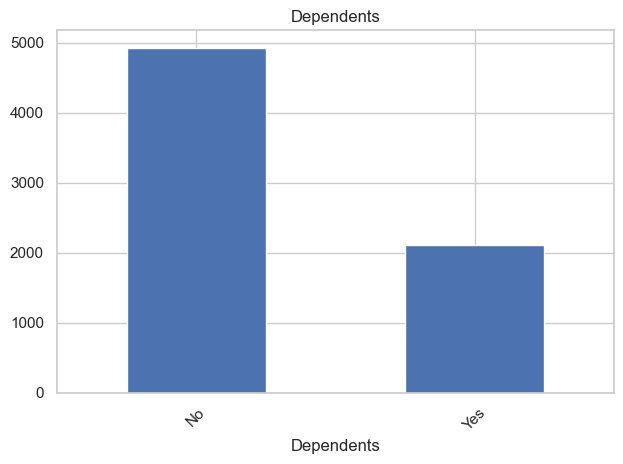

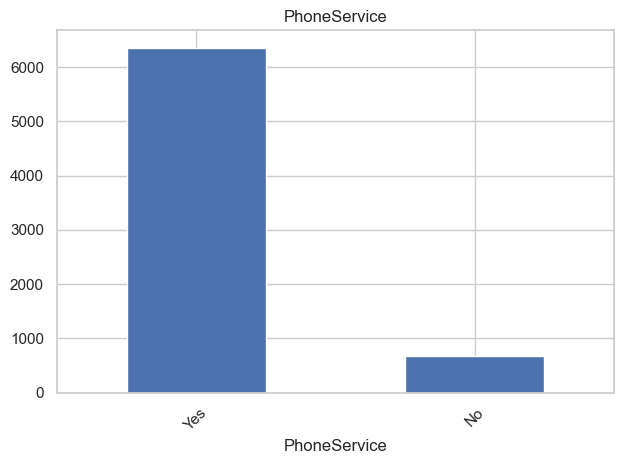

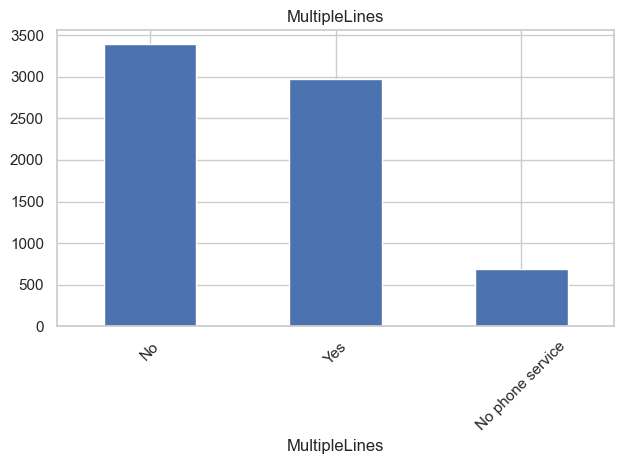

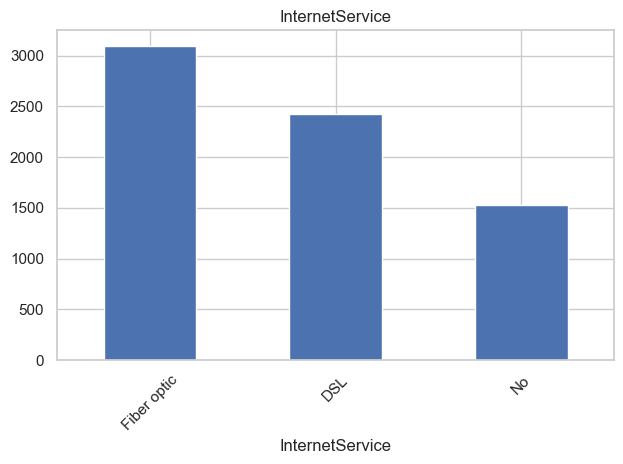

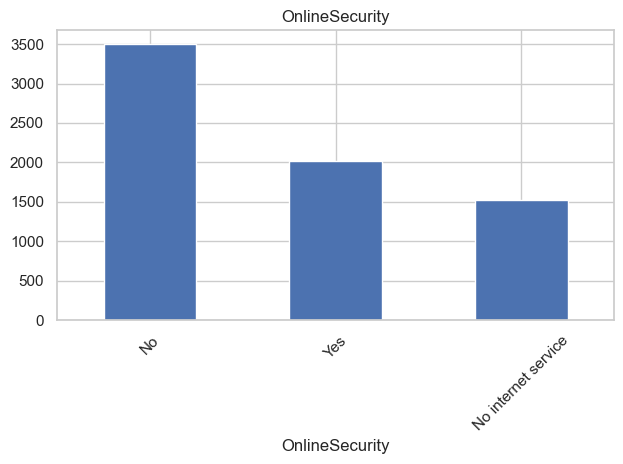

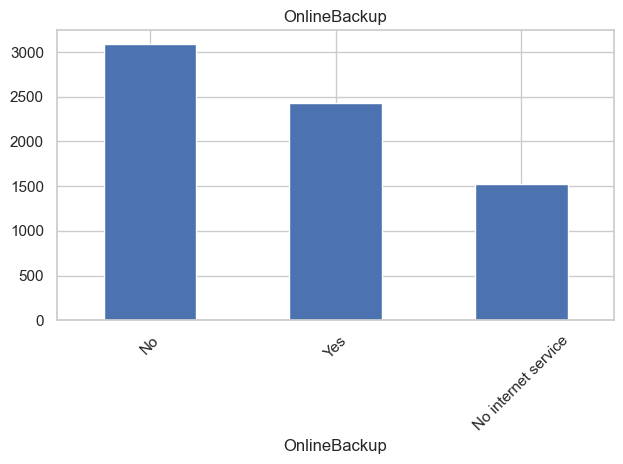

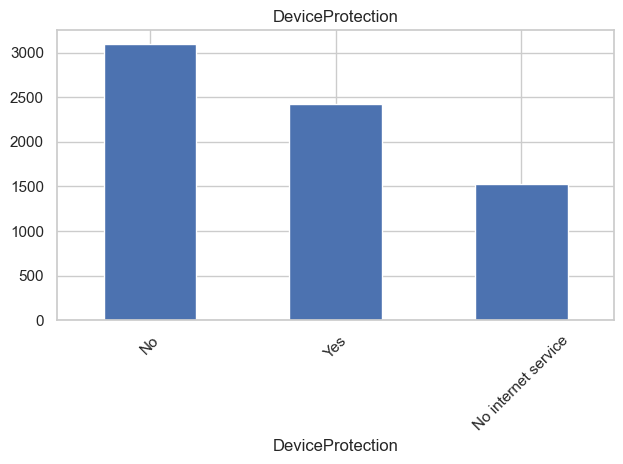

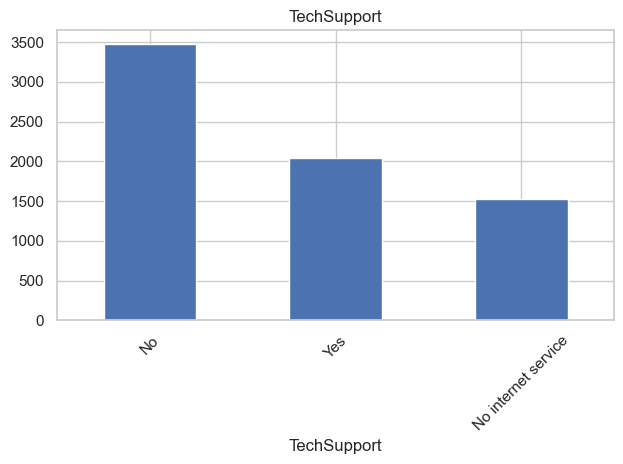

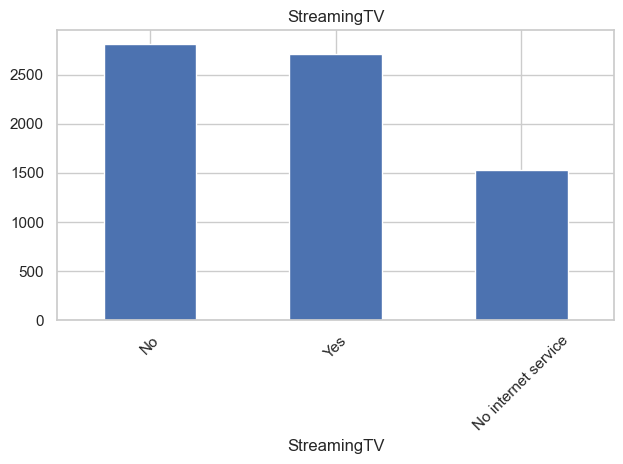

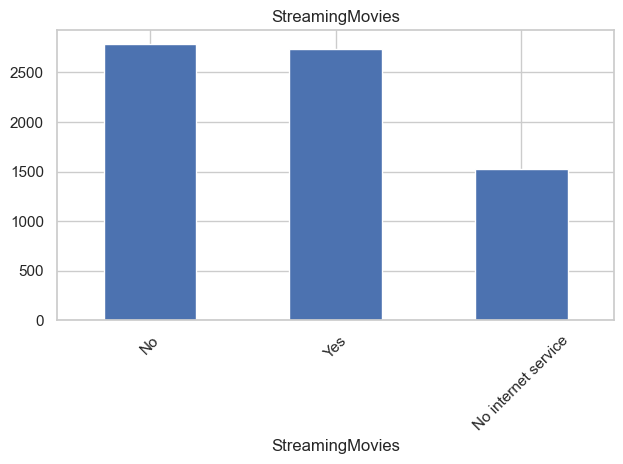

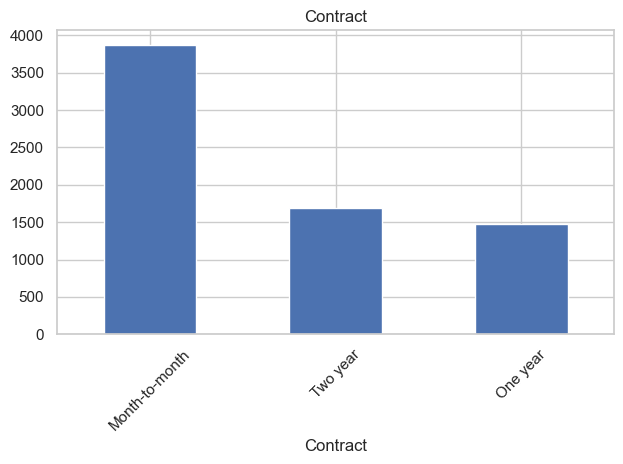

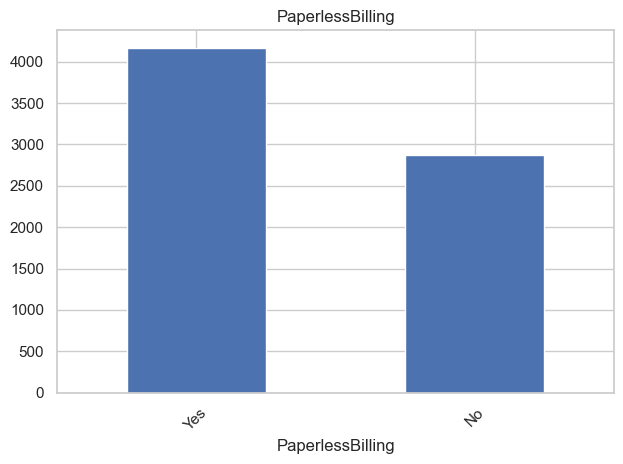

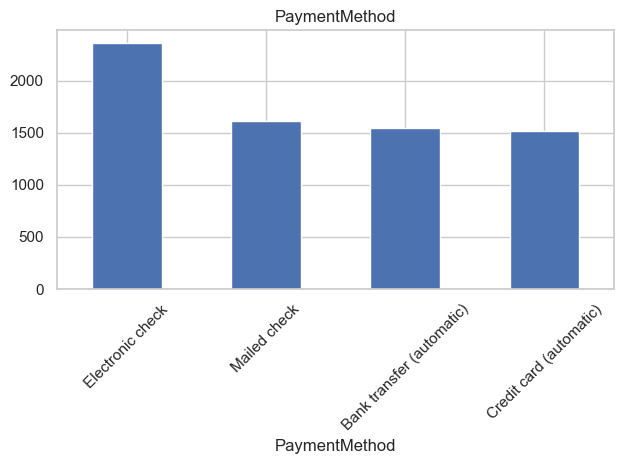

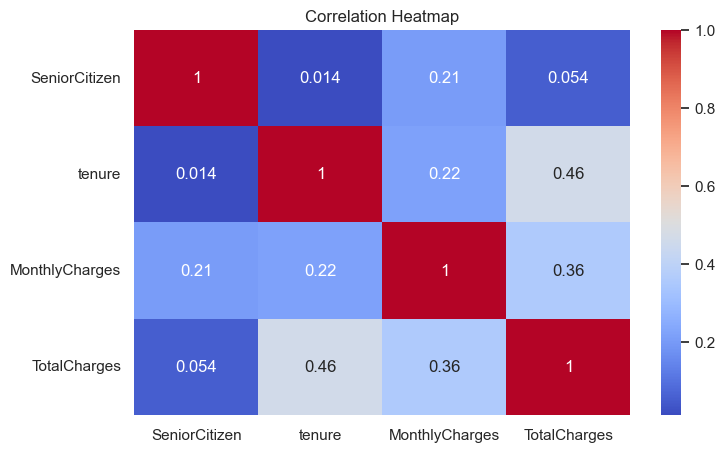

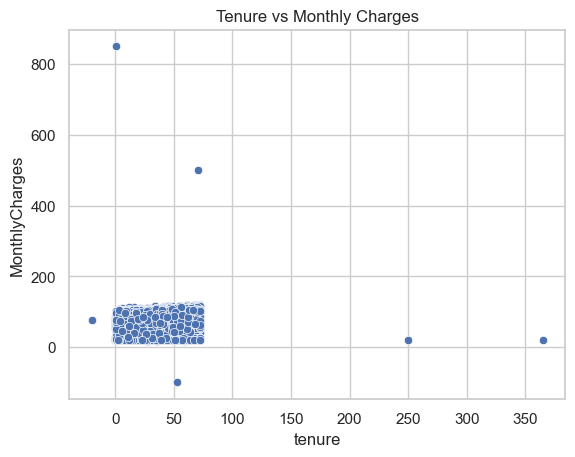

Missing values in each column:
customerID           0
gender               4
SeniorCitizen        0
Partner              0
Dependents           0
tenure               7
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             4
PaperlessBilling     0
PaymentMethod        4
MonthlyCharges       5
TotalCharges        16
Churn                0
dtype: int64


In [7]:

# 1. Churn distribution
df["Churn"].value_counts().plot(kind="bar", title="Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customer Count")
plt.show()


# 2. Numerical feature distributions
df.select_dtypes(include=np.number).hist(figsize=(10, 6), bins=20)
plt.tight_layout()
plt.show()


# 3. Categorical feature distributions
for col in df.select_dtypes(exclude=np.number).columns:
    if col not in ["customerID", "Churn"]:
        df[col].value_counts().head(10).plot(kind="bar", title=col)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


# 4. Correlation heatmap
numeric_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 5))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


# 5. Monthly Charges vs Tenure
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges")
plt.title("Tenure vs Monthly Charges")
plt.show()


# 6. Missing values
print("Missing values in each column:")
print(df.isnull().sum())


## 4. Data cleaning, outlier detection, and feature engineering

IQR outlier detection report (before handling):


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percent
1,MonthlyCharges,35.5125,89.850,54.3375,-45.99375,171.35625,3,0.042626
2,TotalCharges,401.2000,3794.975,3393.7750,-4689.46250,8885.63750,3,0.042692
0,tenure,9.0000,55.000,46.0000,-60.00000,124.00000,2,0.028425


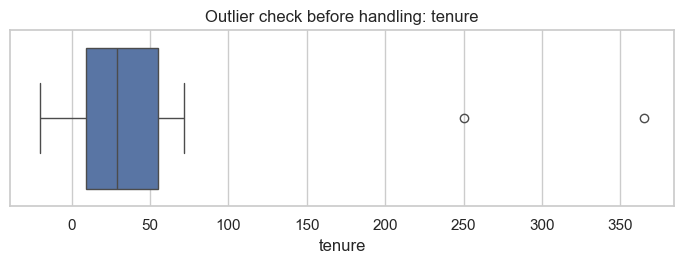

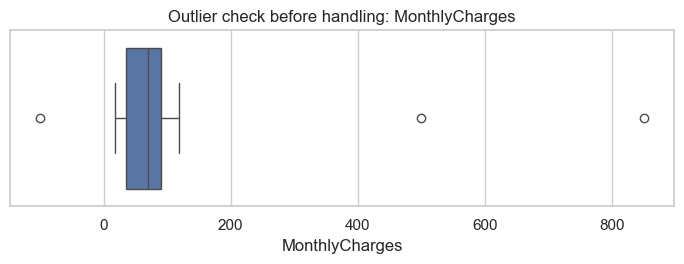

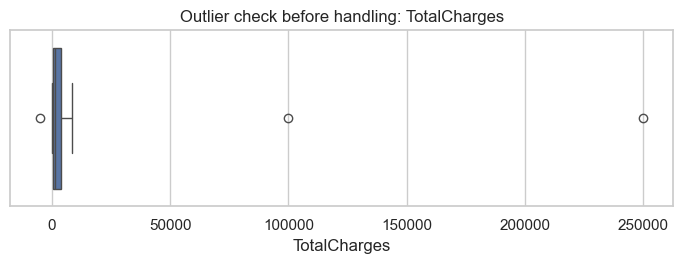

Created AverageChargesPerTenureMonth = TotalCharges / tenure; zero tenure becomes missing and is imputed later.
Missing values after cleaning/conversion/feature engineering:


,Missing Count
AverageChargesPerTenureMonth,23
TotalCharges,16
tenure,7
MonthlyCharges,5
PaymentMethod,4
Contract,4
gender,4


In [4]:
# Remove exact duplicate rows, keeping the first occurrence.
df = df.drop_duplicates().copy()

# The CSV may store TotalCharges as text in some versions. Convert safely.
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Outlier detection using the IQR rule on numeric columns.
# This is a detection report; actual capping is fitted on training data only later.
def iqr_outlier_report(frame, columns):
    rows = []
    for col in columns:
        series = pd.to_numeric(frame[col], errors="coerce").dropna()
        if series.empty:
            continue
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        count = int(((series < low) | (series > high)).sum())
        rows.append({"Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                     "Lower Bound": low, "Upper Bound": high,
                     "Outlier Count": count, "Outlier Percent": 100*count/len(series)})
    return pd.DataFrame(rows).sort_values("Outlier Count", ascending=False)

numeric_for_outliers = [c for c in df.select_dtypes(include=np.number).columns if c not in ["SeniorCitizen"]]
outlier_report = iqr_outlier_report(df, numeric_for_outliers)
print("IQR outlier detection report (before handling):")
display(outlier_report)

for col in numeric_for_outliers:
    fig, ax = plt.subplots(figsize=(7,2.8))
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Outlier check before handling: {col}")
    plt.tight_layout(); plt.show()

# Feature engineering: average monthly spend across tenure where meaningful.
# Avoid customerID as a predictive feature.
if "TotalCharges" in df.columns and "tenure" in df.columns:
    df["AverageChargesPerTenureMonth"] = df["TotalCharges"] / df["tenure"].replace(0, np.nan)
    print("Created AverageChargesPerTenureMonth = TotalCharges / tenure; zero tenure becomes missing and is imputed later.")

# Audit missingness after conversion and feature engineering.
print("Missing values after cleaning/conversion/feature engineering:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing Count").query("`Missing Count` > 0"))

## 5. Simple preprocessing: imputation, encoding, scaling, and IQR capping


In [5]:
# Separate features and targets
DROP_COLUMNS = [c for c in ["customerID"] if c in df.columns]
X_reg = df.drop(columns=DROP_COLUMNS + ["MonthlyCharges", "Churn"], errors="ignore").copy()
y_reg = pd.to_numeric(df["MonthlyCharges"], errors="coerce")

X_clf = df.drop(columns=DROP_COLUMNS + ["Churn", "MonthlyCharges"], errors="ignore").copy()
y_clf = df["Churn"].copy()

# Fill missing target values instead of deleting rows.
y_reg = y_reg.fillna(y_reg.median())
y_clf = y_clf.fillna(y_clf.mode().iloc[0]).astype(str)

# Split the data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

# Identify numerical and categorical features using select_dtypes
num_reg = X_train_reg.select_dtypes(include=np.number).columns.tolist()
cat_reg = X_train_reg.select_dtypes(exclude=np.number).columns.tolist()
num_clf = X_train_clf.select_dtypes(include=np.number).columns.tolist()
cat_clf = X_train_clf.select_dtypes(exclude=np.number).columns.tolist()

# Fill missing feature values before simple IQR capping
for col in num_reg:
    med = X_train_reg[col].median()
    X_train_reg[col] = X_train_reg[col].fillna(med)
    X_test_reg[col] = X_test_reg[col].fillna(med)
for col in cat_reg:
    mode = X_train_reg[col].mode()
    value = mode.iloc[0] if not mode.empty else "Unknown"
    X_train_reg[col] = X_train_reg[col].fillna(value)
    X_test_reg[col] = X_test_reg[col].fillna(value)

for col in num_clf:
    med = X_train_clf[col].median()
    X_train_clf[col] = X_train_clf[col].fillna(med)
    X_test_clf[col] = X_test_clf[col].fillna(med)
for col in cat_clf:
    mode = X_train_clf[col].mode()
    value = mode.iloc[0] if not mode.empty else "Unknown"
    X_train_clf[col] = X_train_clf[col].fillna(value)
    X_test_clf[col] = X_test_clf[col].fillna(value)

# Simple IQR capping: calculate limits from training data and apply to both sets
Q1 = X_train_reg[num_reg].quantile(0.25)
Q3 = X_train_reg[num_reg].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
X_train_reg[num_reg] = X_train_reg[num_reg].clip(lower, upper, axis=1)
X_test_reg[num_reg] = X_test_reg[num_reg].clip(lower, upper, axis=1)

Q1 = X_train_clf[num_clf].quantile(0.25)
Q3 = X_train_clf[num_clf].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
X_train_clf[num_clf] = X_train_clf[num_clf].clip(lower, upper, axis=1)
X_test_clf[num_clf] = X_test_clf[num_clf].clip(lower, upper, axis=1)

# Preprocessing: imputation, one-hot encoding, and scaling
# Imputation is repeated safely in the pipeline; the IQR capping above uses simple code.
def make_preprocessor(numeric_cols, categorical_cols, scale_numeric=True):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols)
    ], remainder="drop", verbose_feature_names_out=False)

preprocessor_reg = make_preprocessor(num_reg, cat_reg)
preprocessor_clf = make_preprocessor(num_clf, cat_clf)

# Keep aliases used by the regression model, tuning, and diagnostics cells
X_train_reg_clean = X_train_reg.copy()
y_train_reg_clean = y_train_reg.copy()
X_test_reg_clean = X_test_reg.copy()
y_test_reg_clean = y_test_reg.copy()

print("Regression train/test shapes:", X_train_reg.shape, X_test_reg.shape)
print("Classification train/test shapes:", X_train_clf.shape, X_test_clf.shape)
print("Numerical features (regression):", num_reg)
print("Categorical features (regression):", cat_reg)
print("Missing feature values are imputed; targets are imputed rather than dropping rows.")
print("Numerical features are capped using simple IQR bounds learned from training data.")


Regression train/test shapes: (5634, 19) (1409, 19)
Classification train/test shapes: (5634, 19) (1409, 19)
Numerical features (regression): ['SeniorCitizen', 'tenure', 'TotalCharges', 'AverageChargesPerTenureMonth']
Categorical features (regression): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Missing feature values are imputed; targets are imputed rather than dropping rows.
Numerical features are capped using simple IQR bounds learned from training data.


## 6. Regression track — all 10 required algorithms (missing targets handled directly)

In [6]:
# ============================================================
# REGRESSION TRACK — ALL 10 REQUIRED ALGORITHMS
# Missing target values have been imputed in the preprocessing cell.
# ============================================================

# Targets were imputed in the preprocessing cell, so no rows are removed.
X_train_reg_clean = X_train_reg.copy()
y_train_reg_clean = y_train_reg.copy()
X_test_reg_clean = X_test_reg.copy()
y_test_reg_clean = y_test_reg.copy()

# Ten required regression algorithms.
regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "ElasticNet Regression": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000),
    "Polynomial Regression (degree 2)": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression())
    ]),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Support Vector Regressor": SVR(C=10, kernel="rbf"),
    "K-Nearest Neighbors Regressor": KNeighborsRegressor(n_neighbors=7)
}

regression_fitted, regression_predictions, regression_rows = {}, {}, []
for name, estimator in regression_models.items():
    print("Training:", name)
    model = Pipeline([
        ("preprocessor", clone(preprocessor_reg)),
        ("model", clone(estimator))
    ])
    model.fit(X_train_reg_clean, y_train_reg_clean)
    pred = model.predict(X_test_reg_clean)
    regression_fitted[name] = model
    regression_predictions[name] = pred
    regression_rows.append({
        "Algorithm": name,
        "R2": r2_score(y_test_reg_clean, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg_clean, pred)),
        "MAE": mean_absolute_error(y_test_reg_clean, pred)
    })

regression_results = pd.DataFrame(regression_rows).sort_values("R2", ascending=False).reset_index(drop=True)
print("REGRESSION COMPARISON — all 10 algorithms")
display(regression_results.style.format({"R2":"{:.4f}", "RMSE":"{:.4f}", "MAE":"{:.4f}"}))

Training: Linear Regression
Training: Ridge Regression
Training: Lasso Regression
Training: ElasticNet Regression
Training: Polynomial Regression (degree 2)
Training: Decision Tree Regressor
Training: Random Forest Regressor
Training: Gradient Boosting Regressor
Training: Support Vector Regressor
Training: K-Nearest Neighbors Regressor
REGRESSION COMPARISON — all 10 algorithms


,Algorithm,R2,RMSE,MAE
0,Support Vector Regressor,0.9987,1.1054,0.8078
1,Lasso Regression,0.9984,1.2076,0.9282
2,Ridge Regression,0.9983,1.2341,0.9494
3,Linear Regression,0.9983,1.2369,0.9508
4,ElasticNet Regression,0.9981,1.2960,0.9814
5,Polynomial Regression (degree 2),0.9934,2.4397,1.6564
6,Decision Tree Regressor,0.9921,2.6773,1.7268
7,Gradient Boosting Regressor,0.9880,3.2931,1.5992
8,Random Forest Regressor,0.9773,4.5340,1.5831
9,K-Nearest Neighbors Regressor,0.9552,6.3654,2.2163


### Regression: hyperparameter tuning, five-fold CV, and diagnostics

Ridge best params: {'model__alpha': 0.01} CV R2: 0.8858 test R2: 0.9983 test RMSE: 1.2369
Decision Tree best params: {'model__max_depth': None, 'model__min_samples_split': 10} CV R2: 0.7608 test R2: 0.9901 test RMSE: 2.9881


,Algorithm,5-fold CV R2 mean,5-fold CV R2 std,Fold scores
0,Support Vector Regressor,0.885862,0.145453,"[0.9954, 0.9959, 0.8667, 0.9606, 0.6107]"
1,Lasso Regression,0.885781,0.145574,"[0.9954, 0.9954, 0.8669, 0.9609, 0.6102]"


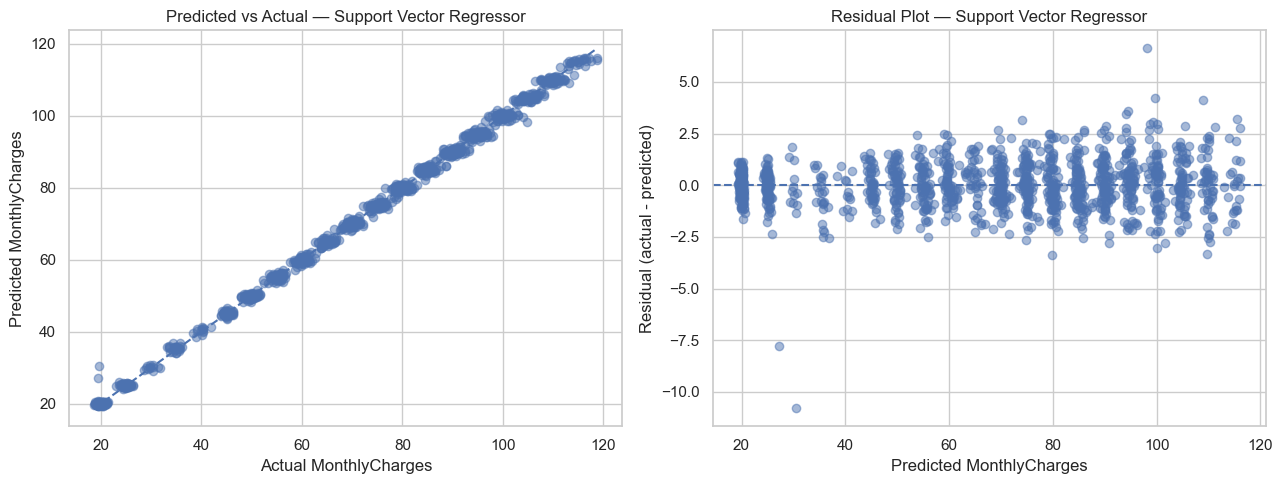

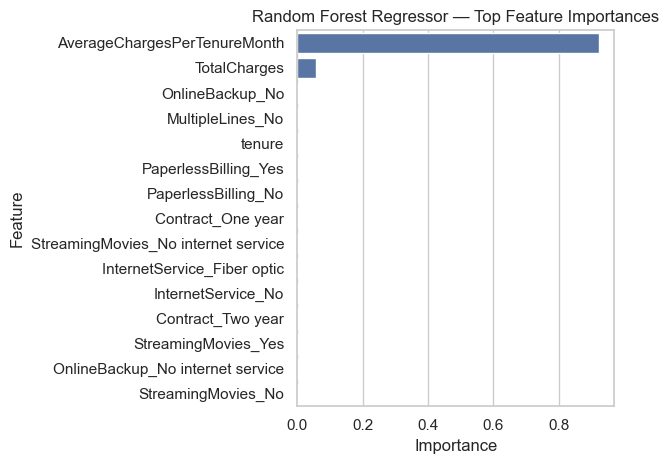

,Feature,Coefficient,AbsCoefficient
16,InternetService_Fiber optic,14.039645,14.039645
15,InternetService_DSL,-8.841261,8.841261
35,StreamingMovies_Yes,7.694658,7.694658
32,StreamingTV_Yes,7.082032,7.082032
11,PhoneService_Yes,6.283417,6.283417
10,PhoneService_No,-6.283417,6.283417
13,MultipleLines_No phone service,-6.283417,6.283417
14,MultipleLines_Yes,5.477204,5.477204
17,InternetService_No,-5.198384,5.198384
22,OnlineBackup_No internet service,-5.198384,5.198384


In [7]:
# Tune two models with GridSearchCV.
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ridge_search = GridSearchCV(
    Pipeline([("preprocessor", clone(preprocessor_reg)), ("model", Ridge())]),
    {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]}, scoring="r2", cv=cv_reg, n_jobs=-1
)
ridge_search.fit(X_train_reg_clean, y_train_reg_clean)
tree_search = GridSearchCV(
    Pipeline([("preprocessor", clone(preprocessor_reg)), ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_split": [2, 5, 10]},
    scoring="r2", cv=cv_reg, n_jobs=-1
)
tree_search.fit(X_train_reg_clean, y_train_reg_clean)
for label, search in [("Ridge", ridge_search), ("Decision Tree", tree_search)]:
    pred = search.predict(X_test_reg_clean)
    print(label, "best params:", search.best_params_, "CV R2:", round(search.best_score_,4),
          "test R2:", round(r2_score(y_test_reg_clean,pred),4), "test RMSE:", round(np.sqrt(mean_squared_error(y_test_reg_clean,pred)),4))

# Cross-validation for the two best baseline models from the held-out comparison.
top_reg = regression_results["Algorithm"].head(2).tolist()
cv_rows=[]
for name in top_reg:
    scores = cross_val_score(clone(regression_fitted[name]), X_train_reg_clean, y_train_reg_clean, cv=cv_reg, scoring="r2", n_jobs=-1)
    cv_rows.append({"Algorithm":name,"5-fold CV R2 mean":scores.mean(),"5-fold CV R2 std":scores.std(),"Fold scores":np.round(scores,4).tolist()})
display(pd.DataFrame(cv_rows))

best_reg_name = regression_results.iloc[0]["Algorithm"]
best_reg_model = regression_fitted[best_reg_name]
best_pred = regression_predictions[best_reg_name]
residuals = y_test_reg_clean.to_numpy() - best_pred
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(y_test_reg_clean, best_pred, alpha=.5)
lo=min(y_test_reg_clean.min(),best_pred.min()); hi=max(y_test_reg_clean.max(),best_pred.max())
axes[0].plot([lo,hi],[lo,hi],"--")
axes[0].set(title=f"Predicted vs Actual — {best_reg_name}",xlabel="Actual MonthlyCharges",ylabel="Predicted MonthlyCharges")
axes[1].scatter(best_pred,residuals,alpha=.5)
axes[1].axhline(0,linestyle="--")
axes[1].set(title=f"Residual Plot — {best_reg_name}",xlabel="Predicted MonthlyCharges",ylabel="Residual (actual - predicted)")
plt.tight_layout(); plt.show()

# Feature importance for a tree-based model; pipeline preprocessing exposes transformed feature names.
tree_model = regression_fitted.get("Random Forest Regressor")
if tree_model is not None:
    try:
        feature_names = tree_model.named_steps["preprocessor"].get_feature_names_out()
        importances = tree_model.named_steps["model"].feature_importances_
        importance_df = pd.DataFrame({"Feature":feature_names,"Importance":importances}).sort_values("Importance",ascending=False).head(15)
        sns.barplot(data=importance_df, x="Importance", y="Feature")
        plt.title("Random Forest Regressor — Top Feature Importances"); plt.tight_layout(); plt.show()
    except Exception as e:
        print("Feature importance plot could not be created:",e)

# Coefficient interpretation for Linear Regression when available.
try:
    lin = regression_fitted["Linear Regression"]
    names = lin.named_steps["preprocessor"].get_feature_names_out()
    coef = lin.named_steps["model"].coef_
    display(pd.DataFrame({"Feature":names,"Coefficient":coef}).assign(AbsCoefficient=lambda x:x.Coefficient.abs()).sort_values("AbsCoefficient",ascending=False).head(15))
except Exception as e:
    print("Coefficient table unavailable:",e)

## 7. Classification track — Part A (Review 1) and Part B (Review 2), all 10 algorithms

In [11]:
# Part A: first five; Part B: final five
classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree Classifier": DecisionTreeClassifier(
        max_depth=8, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Support Vector Machine (SVC)": SVC(
        C=1.0, kernel="rbf", probability=True,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE,
        n_jobs=-1, class_weight="balanced_subsample"
    ),
    "AdaBoost Classifier": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
    ),
    "Gradient Boosting Classifier": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "Bagging Classifier": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "MLP Classifier": MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=False,
    random_state=RANDOM_STATE
)
}

# Clean target labels before identifying classes
y_train_clf = y_train_clf.astype("string").str.strip()
y_test_clf = y_test_clf.astype("string").str.strip()

y_train_clf = y_train_clf.replace("", pd.NA)
y_test_clf = y_test_clf.replace("", pd.NA)

mode_value = y_train_clf.mode().iloc[0]
y_train_clf = y_train_clf.fillna(mode_value)
y_test_clf = y_test_clf.fillna(mode_value)

# Identify classes after cleaning
classes = np.unique(y_train_clf)

classification_fitted = {}
classification_predictions = {}
classification_rows = []
classification_scores = {}

for name, estimator in classification_models.items():

    print("Training:", name)

    model = Pipeline([
        ("preprocessor", clone(preprocessor_clf)),
        ("model", clone(estimator))
    ])

    model.fit(X_train_clf, y_train_clf)
    pred = model.predict(X_test_clf)

    classification_fitted[name] = model
    classification_predictions[name] = pred

    row = {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test_clf, pred),
        "Precision (weighted)": precision_score(
            y_test_clf, pred, average="weighted", zero_division=0
        ),
        "Recall (weighted)": recall_score(
            y_test_clf, pred, average="weighted", zero_division=0
        ),
        "F1 (weighted)": f1_score(
            y_test_clf, pred, average="weighted", zero_division=0
        )
    }

    # ROC-AUC
    try:
        if hasattr(model, "predict_proba"):
            proba = model.predict_proba(X_test_clf)
            classification_scores[name] = proba

            if len(classes) == 2:
                positive_index = list(model.classes_).index(classes[1])
                row["ROC-AUC"] = roc_auc_score(
                    y_test_clf, proba[:, positive_index]
                )
            else:
                row["ROC-AUC"] = roc_auc_score(
                    y_test_clf, proba,
                    multi_class="ovr", average="weighted",
                    labels=model.classes_
                )
        else:
            row["ROC-AUC"] = np.nan

    except Exception as e:
        row["ROC-AUC"] = np.nan
        print("ROC-AUC unavailable for", name, ":", e)

    classification_rows.append(row)

# Comparison table
classification_results = pd.DataFrame(classification_rows)
classification_results = classification_results.sort_values(
    "F1 (weighted)", ascending=False
).reset_index(drop=True)

print("PART A — REVIEW 1 (first five algorithms)")
display(
    classification_results[
        classification_results["Algorithm"].isin(
            list(classification_models)[:5]
        )
    ]
)

print("PART B — REVIEW 2 (last five algorithms)")
display(
    classification_results[
        classification_results["Algorithm"].isin(
            list(classification_models)[5:]
        )
    ]
)

print("CONSOLIDATED 10-ALGORITHM CLASSIFICATION COMPARISON")
display(classification_results.round(4))

Training: Logistic Regression
Training: K-Nearest Neighbors
Training: Gaussian Naive Bayes
Training: Decision Tree Classifier
Training: Support Vector Machine (SVC)
Training: Random Forest Classifier
Training: AdaBoost Classifier
Training: Gradient Boosting Classifier
Training: Bagging Classifier
Training: MLP Classifier
PART A — REVIEW 1 (first five algorithms)


,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
2,K-Nearest Neighbors,0.774308,0.774308,0.774308,0.774308,0.805962
5,Support Vector Machine (SVC),0.745919,0.798025,0.745919,0.758813,0.818045
7,Logistic Regression,0.735273,0.796017,0.735273,0.749429,0.840830
8,Decision Tree Classifier,0.713982,0.783833,0.713982,0.729855,0.782353
9,Gaussian Naive Bayes,0.696238,0.794409,0.696238,0.713983,0.805906


PART B — REVIEW 2 (last five algorithms)


,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,Gradient Boosting Classifier,0.798439,0.788534,0.798439,0.790852,0.841719
1,AdaBoost Classifier,0.796309,0.787777,0.796309,0.790411,0.840310
3,Bagging Classifier,0.780696,0.770066,0.780696,0.773345,0.815903
4,Random Forest Classifier,0.778566,0.765231,0.778566,0.768319,0.818471
6,MLP Classifier,0.753726,0.750237,0.753726,0.751865,0.782451


CONSOLIDATED 10-ALGORITHM CLASSIFICATION COMPARISON


,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,Gradient Boosting Classifier,0.7984,0.7885,0.7984,0.7909,0.8417
1,AdaBoost Classifier,0.7963,0.7878,0.7963,0.7904,0.8403
2,K-Nearest Neighbors,0.7743,0.7743,0.7743,0.7743,0.8060
3,Bagging Classifier,0.7807,0.7701,0.7807,0.7733,0.8159
4,Random Forest Classifier,0.7786,0.7652,0.7786,0.7683,0.8185
5,Support Vector Machine (SVC),0.7459,0.7980,0.7459,0.7588,0.8180
6,MLP Classifier,0.7537,0.7502,0.7537,0.7519,0.7825
7,Logistic Regression,0.7353,0.7960,0.7353,0.7494,0.8408
8,Decision Tree Classifier,0.7140,0.7838,0.7140,0.7299,0.7824
9,Gaussian Naive Bayes,0.6962,0.7944,0.6962,0.7140,0.8059


### Classification: confusion matrices, ROC curves, tuning, and cross-validation

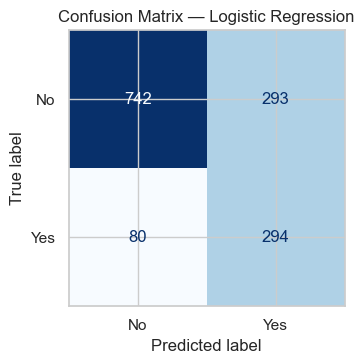

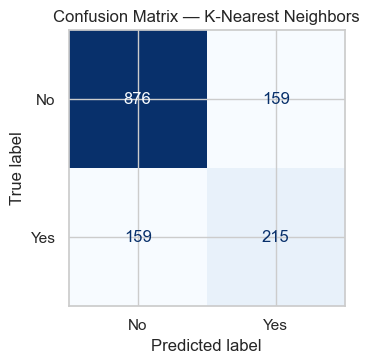

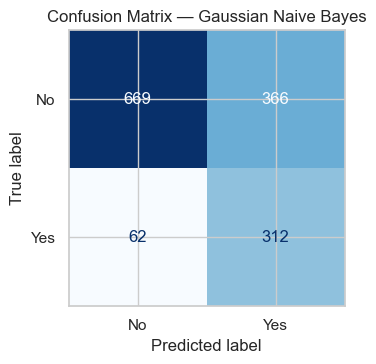

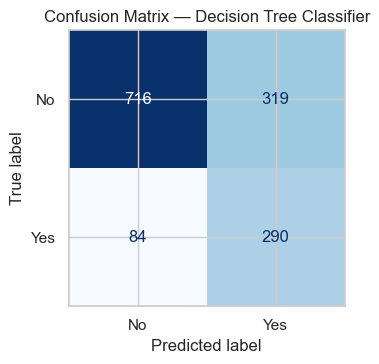

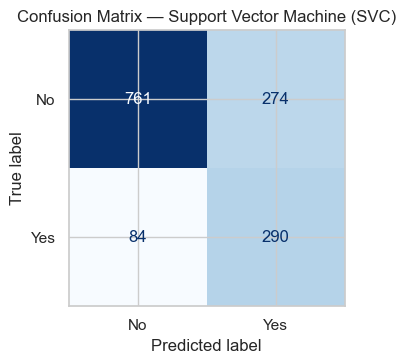

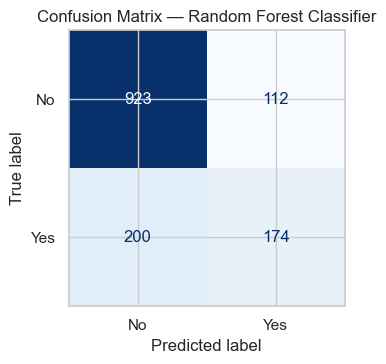

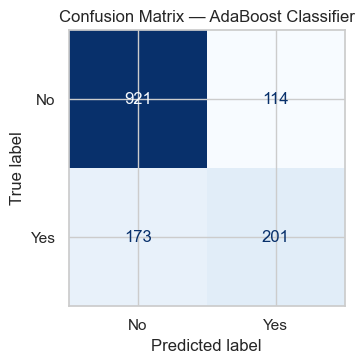

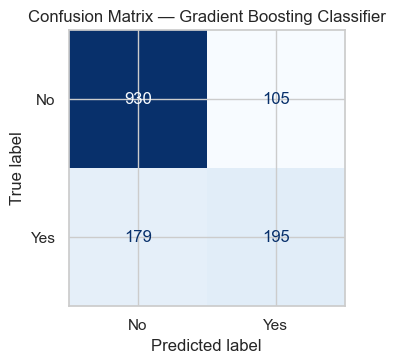

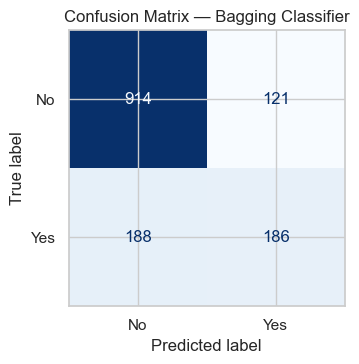

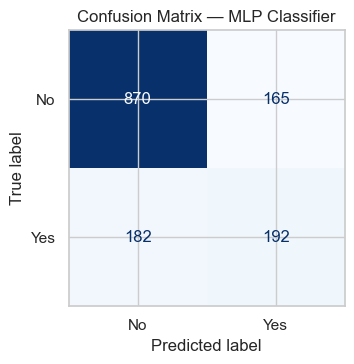

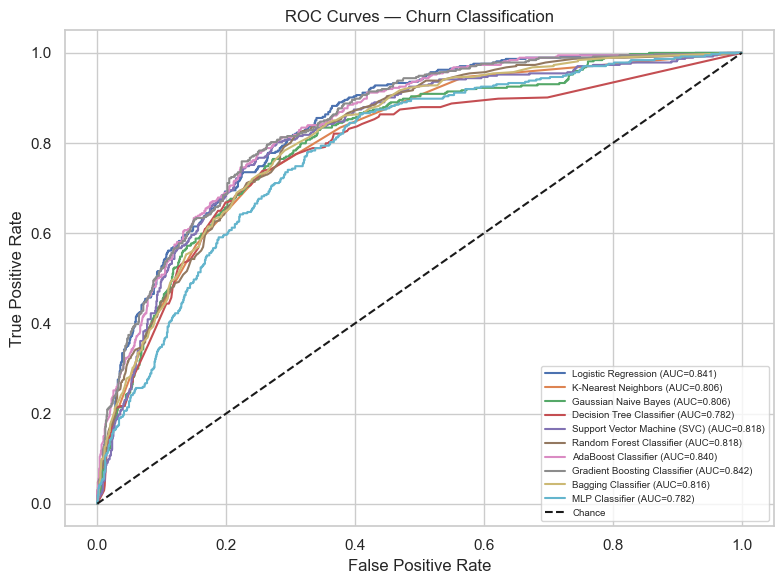

Logistic Regression best params: {'model__C': 0.1} best CV weighted F1: 0.7634 test weighted F1: 0.7486
Random Forest best params: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__max_depth': None} best CV weighted F1: 0.7888 test weighted F1: 0.7797


,Algorithm,5-fold weighted F1 mean,std,Fold scores
0,Gradient Boosting Classifier,0.793197,0.010643,"[0.7866, 0.7764, 0.8047, 0.7949, 0.8034]"
1,AdaBoost Classifier,0.793928,0.009495,"[0.7922, 0.7791, 0.7979, 0.8084, 0.7921]"


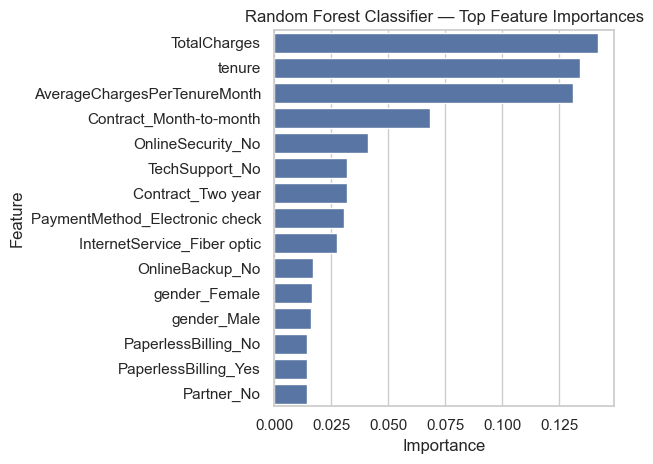

In [12]:
# Confusion matrix for every algorithm (required evaluation artifact).
for name, pred in classification_predictions.items():
    fig, ax = plt.subplots(figsize=(4.5,3.8))
    ConfusionMatrixDisplay.from_predictions(y_test_clf, pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout(); plt.show()

# ROC curve for binary churn classification. Positive class is Churn='Yes' if present.
positive_label = "Yes" if "Yes" in list(classes) else sorted(classes)[-1]
y_test_binary = (y_test_clf == positive_label).astype(int)
plt.figure(figsize=(8,6))
for name, model in classification_fitted.items():
    est = model.named_steps["model"]
    try:
        if hasattr(est,"predict_proba"):
            scores = model.predict_proba(X_test_clf)[:, list(est.classes_).index(positive_label)]
        elif hasattr(est,"decision_function"):
            raw = model.decision_function(X_test_clf)
            scores = raw if len(est.classes_)==2 and est.classes_[1]==positive_label else -raw
        else:
            continue
        from sklearn.metrics import roc_curve, auc
        fpr,tpr,_ = roc_curve(y_test_binary,scores)
        plt.plot(fpr,tpr,label=f"{name} (AUC={auc(fpr,tpr):.3f})")
    except Exception as e:
        print("ROC curve skipped for",name,":",e)
plt.plot([0,1],[0,1],"k--",label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves — Churn Classification")
plt.legend(fontsize=7,loc="lower right"); plt.tight_layout(); plt.show()

# Hyperparameter tuning for Logistic Regression and Random Forest.
cv_clf = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
log_search = GridSearchCV(
    Pipeline([("preprocessor",clone(preprocessor_clf)),("model",LogisticRegression(max_iter=3000,class_weight="balanced",random_state=RANDOM_STATE))]),
    {"model__C":[0.1,1.0,10.0]}, scoring="f1_weighted", cv=cv_clf, n_jobs=-1
)
log_search.fit(X_train_clf,y_train_clf)
rf_search = RandomizedSearchCV(
    Pipeline([("preprocessor",clone(preprocessor_clf)),("model",RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1,class_weight="balanced_subsample"))]),
    {"model__n_estimators":[100,150,200],"model__max_depth":[None,8,15],"model__min_samples_split":[2,5,10]},
    n_iter=8, scoring="f1_weighted", cv=cv_clf, random_state=RANDOM_STATE, n_jobs=-1
)
rf_search.fit(X_train_clf,y_train_clf)
for name, search in [("Logistic Regression",log_search),("Random Forest",rf_search)]:
    pred=search.predict(X_test_clf)
    print(name,"best params:",search.best_params_,"best CV weighted F1:",round(search.best_score_,4),
          "test weighted F1:",round(f1_score(y_test_clf,pred,average="weighted"),4))

# Five-fold CV for the two best baseline classifiers based on weighted F1.
top_clf = classification_results["Algorithm"].head(2).tolist()
cv_clf_rows=[]
for name in top_clf:
    scores=cross_val_score(clone(classification_fitted[name]),X_train_clf,y_train_clf,cv=cv_clf,scoring="f1_weighted",n_jobs=-1)
    cv_clf_rows.append({"Algorithm":name,"5-fold weighted F1 mean":scores.mean(),"std":scores.std(),"Fold scores":np.round(scores,4).tolist()})
display(pd.DataFrame(cv_clf_rows))

# Feature importance for random forest if desired.
try:
    rf_model=classification_fitted["Random Forest Classifier"]
    feat_names=rf_model.named_steps["preprocessor"].get_feature_names_out()
    imp=rf_model.named_steps["model"].feature_importances_
    imp_df=pd.DataFrame({"Feature":feat_names,"Importance":imp}).sort_values("Importance",ascending=False).head(15)
    sns.barplot(data=imp_df,x="Importance",y="Feature")
    plt.title("Random Forest Classifier — Top Feature Importances"); plt.tight_layout(); plt.show()
except Exception as e:
    print("Classification feature importance unavailable:",e)

## 8. Clustering track — K-Means and Agglomerative Hierarchical Clustering

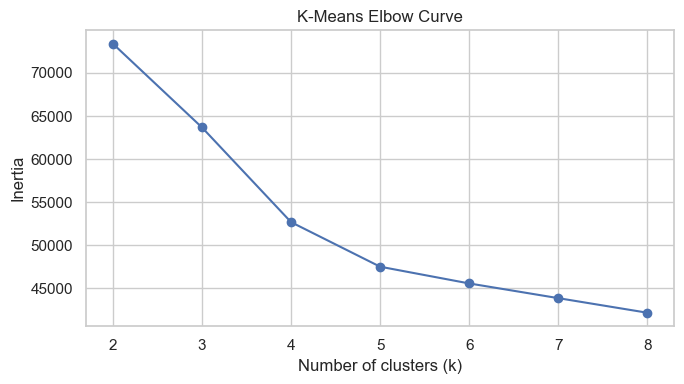

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.214490,1.868037,1331.599102
1,Agglomerative Hierarchical,0.207578,1.025889,1436.385120


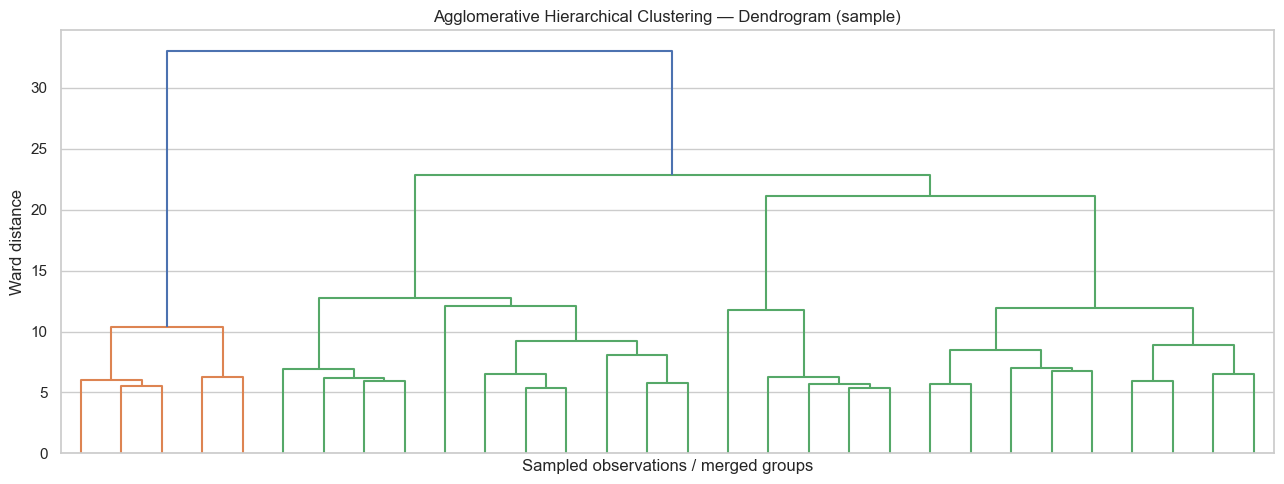

PCA explained variance ratio: [0.1906 0.169 ] total: 0.3596


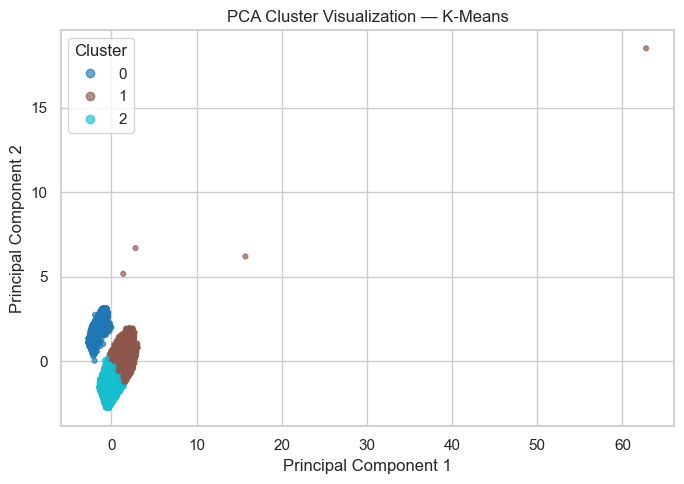

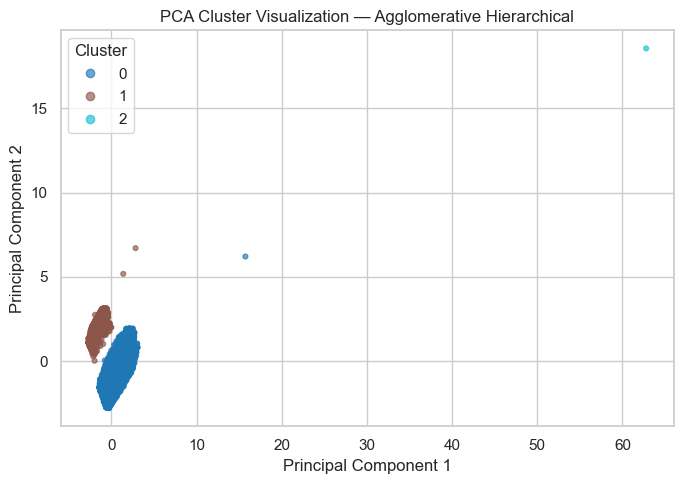

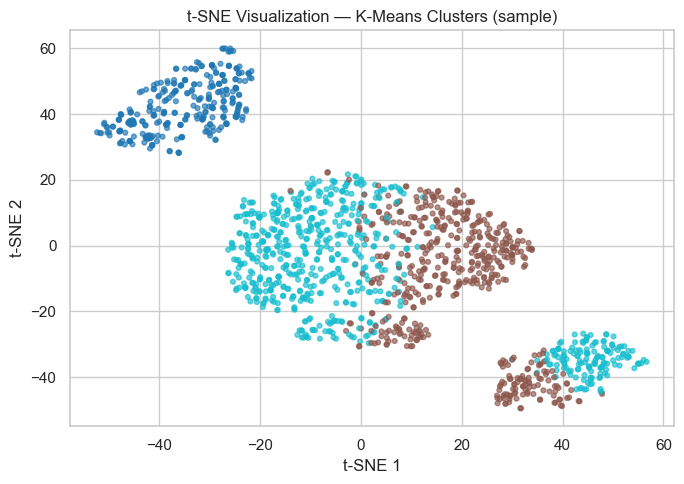

Post-hoc churn distribution within K-Means clusters (interpretation only):


Churn,No,Yes
K-Means cluster,,
0,0.925853,0.074147
1,0.863808,0.136192
2,0.543949,0.456051


In [13]:
# Use predictors only; neither Churn nor MonthlyCharges is included in clustering inputs.
cluster_X = df.drop(columns=DROP_COLUMNS + ["Churn", "MonthlyCharges"], errors="ignore").copy()
cluster_num = cluster_X.select_dtypes(include=np.number).columns.tolist()
cluster_cat = cluster_X.select_dtypes(exclude=np.number).columns.tolist()
cluster_preprocessor = make_preprocessor(cluster_num, cluster_cat, scale_numeric=True)
X_cluster = cluster_preprocessor.fit_transform(cluster_X)
# Ensure finite dense matrix for PCA/clustering.
X_cluster = np.asarray(X_cluster, dtype=float)
if not np.isfinite(X_cluster).all():
    raise ValueError("Clustering preprocessing produced non-finite values. Inspect missing-value handling.")

# Elbow curve for K-Means.
ks=range(2,9); inertias=[]
for k in ks:
    km=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=10)
    km.fit(X_cluster); inertias.append(km.inertia_)
plt.figure(figsize=(7,4)); plt.plot(list(ks),inertias,marker="o")
plt.title("K-Means Elbow Curve"); plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia")
plt.tight_layout(); plt.show()

# Use k=3 as a reproducible starting point; discuss whether the elbow suggests another k.
K_CLUSTERS=3
kmeans=KMeans(n_clusters=K_CLUSTERS,random_state=RANDOM_STATE,n_init=10)
kmeans_labels=kmeans.fit_predict(X_cluster)
agglomerative=AgglomerativeClustering(n_clusters=K_CLUSTERS,linkage="ward")
agglomerative_labels=agglomerative.fit_predict(X_cluster)

# Clustering metrics (no ground-truth labels used in fitting).
def cluster_metrics(name, X, labels):
    n_unique=len(np.unique(labels))
    if n_unique < 2 or n_unique >= len(labels):
        return {"Algorithm":name,"Silhouette Score":np.nan,"Davies-Bouldin Index":np.nan,"Calinski-Harabasz Index":np.nan}
    # Silhouette on a fixed random sample to control runtime on larger datasets.
    sil=silhouette_score(X,labels,sample_size=min(2000,len(labels)),random_state=RANDOM_STATE)
    return {"Algorithm":name,"Silhouette Score":sil,"Davies-Bouldin Index":davies_bouldin_score(X,labels),"Calinski-Harabasz Index":calinski_harabasz_score(X,labels)}
clustering_results=pd.DataFrame([
    cluster_metrics("K-Means",X_cluster,kmeans_labels),
    cluster_metrics("Agglomerative Hierarchical",X_cluster,agglomerative_labels)
])
display(clustering_results)

# Dendrogram on a sample to keep the plot readable and memory use reasonable.
sample_n=min(250,len(X_cluster))
rng=np.random.RandomState(RANDOM_STATE)
sample_idx=rng.choice(len(X_cluster),size=sample_n,replace=False)
Z=linkage(X_cluster[sample_idx],method="ward")
plt.figure(figsize=(13,5)); dendrogram(Z,no_labels=True,truncate_mode="lastp",p=30)
plt.title("Agglomerative Hierarchical Clustering — Dendrogram (sample)")
plt.xlabel("Sampled observations / merged groups"); plt.ylabel("Ward distance")
plt.tight_layout(); plt.show()

# PCA visualization (two components) for every clustering algorithm.
pca=PCA(n_components=2,random_state=RANDOM_STATE)
X_pca=pca.fit_transform(X_cluster)
print("PCA explained variance ratio:",np.round(pca.explained_variance_ratio_,4),"total:",round(pca.explained_variance_ratio_.sum(),4))
for name, labels in [("K-Means",kmeans_labels),("Agglomerative Hierarchical",agglomerative_labels)]:
    plt.figure(figsize=(7,5)); scatter=plt.scatter(X_pca[:,0],X_pca[:,1],c=labels,s=12,alpha=.65,cmap="tab10")
    plt.title(f"PCA Cluster Visualization — {name}"); plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
    plt.legend(*scatter.legend_elements(),title="Cluster",loc="best"); plt.tight_layout(); plt.show()

# t-SNE for at least one algorithm, on a sample to keep runtime manageable.
tsne_n=min(1500,len(X_cluster))
tsne_idx=rng.choice(len(X_cluster),size=tsne_n,replace=False)
tsne=TSNE(n_components=2,random_state=RANDOM_STATE,init="pca",learning_rate="auto",perplexity=min(30,max(5,(tsne_n-1)//3)))
X_tsne=tsne.fit_transform(X_cluster[tsne_idx])
plt.figure(figsize=(7,5)); plt.scatter(X_tsne[:,0],X_tsne[:,1],c=kmeans_labels[tsne_idx],s=12,alpha=.65,cmap="tab10")
plt.title("t-SNE Visualization — K-Means Clusters (sample)"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

# Optional post-hoc validation only; labels are never passed to clustering fit.
if "Churn" in df:
    posthoc = pd.crosstab(pd.Series(kmeans_labels,name="K-Means cluster"),df["Churn"].fillna("Missing"),normalize="index")
    print("Post-hoc churn distribution within K-Means clusters (interpretation only):")
    display(posthoc)

## 9. Final summary and model selection

In [14]:
print("BEST BASELINE REGRESSION MODEL:", regression_results.iloc[0]["Algorithm"])
display(regression_results.head(3))
print("BEST BASELINE CLASSIFICATION MODEL (weighted F1):", classification_results.iloc[0]["Algorithm"])
display(classification_results.head(3))
print("CLUSTERING COMPARISON:")
display(clustering_results)

print("\nInterpretation checklist — write conclusions based on your actual outputs:")
print("1. Regression: compare R2 (higher is better), RMSE and MAE (lower is better).")
print("2. Classification: compare weighted F1, recall, precision, accuracy and ROC-AUC; inspect false negatives for churn.")
print("3. Clustering: higher Silhouette and Calinski-Harabasz and lower Davies-Bouldin generally indicate better separation.")
print("4. Explain the limitations of using MonthlyCharges as the regression target and Churn as the classification target.")
print("5. Clustering was fitted without churn labels; any churn cross-tab is post-hoc interpretation only.")

BEST BASELINE REGRESSION MODEL: Support Vector Regressor


,Algorithm,R2,RMSE,MAE
0,Support Vector Regressor,0.998650,1.105409,0.807839
1,Lasso Regression,0.998389,1.207633,0.928204
2,Ridge Regression,0.998318,1.234126,0.949387


BEST BASELINE CLASSIFICATION MODEL (weighted F1): Gradient Boosting Classifier


,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,Gradient Boosting Classifier,0.798439,0.788534,0.798439,0.790852,0.841719
1,AdaBoost Classifier,0.796309,0.787777,0.796309,0.790411,0.840310
2,K-Nearest Neighbors,0.774308,0.774308,0.774308,0.774308,0.805962


CLUSTERING COMPARISON:


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.214490,1.868037,1331.599102
1,Agglomerative Hierarchical,0.207578,1.025889,1436.385120



Interpretation checklist — write conclusions based on your actual outputs:
1. Regression: compare R2 (higher is better), RMSE and MAE (lower is better).
2. Classification: compare weighted F1, recall, precision, accuracy and ROC-AUC; inspect false negatives for churn.
3. Clustering: higher Silhouette and Calinski-Harabasz and lower Davies-Bouldin generally indicate better separation.
4. Explain the limitations of using MonthlyCharges as the regression target and Churn as the classification target.
5. Clustering was fitted without churn labels; any churn cross-tab is post-hoc interpretation only.


## 10. Save key result tables

In [15]:
# Export tables to the current working directory for your report/README.
regression_results.to_csv("regression_results.csv",index=False)
classification_results.to_csv("classification_results.csv",index=False)
clustering_results.to_csv("clustering_results.csv",index=False)
print("Saved regression_results.csv, classification_results.csv, and clustering_results.csv to:",os.getcwd())

Saved regression_results.csv, classification_results.csv, and clustering_results.csv to: C:\Users\srina\Downloads\telecom_churn_capstone_full_corrected\telecom_churn_capstone_full_corrected\notebooks


## Submission checklist

- [ ] Run **Kernel → Restart Kernel and Run All Cells** and confirm no errors.
- [ ] Keep notebook outputs visible after running.
- [ ] Add original written observations under the EDA plots and interpret the actual metrics.
- [ ] Review model assumptions and explain why `MonthlyCharges` is the regression target and `Churn` the classification target.
- [ ] Include this notebook, the assigned dataset (if permitted), README, and `requirements.txt` in GitHub.
- [ ] Make meaningful commits over time; do not submit a single bulk commit.
- [ ] Cite AI assistance in the README as required by the course guidelines, and ensure your analysis/interpretation is your own.

**AI assistance disclosure:** Code scaffolding was prepared with AI assistance. The project owner must independently verify the results and write their own data interpretations, conclusions, and viva explanations.

**Note:** This simplified version imputes missing target values as requested. Because imputed targets are estimates, report this choice clearly and, where possible, evaluate test metrics on originally observed target values for a more reliable assessment.
